In [2]:
%pip install datasets
%pip install ftfy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from datasets import load_dataset

dataset = load_dataset("valurank/News_Articles_Categorization")
dataset1 = load_dataset("valurank/Topic_Classification")
dataset2 = load_dataset("AiresPucrs/News-Category-Dataset")
dataset3 = load_dataset("SetFit/bbc-news")
dataset4 = load_dataset("SetFit/20_newsgroups")
dataset5 = load_dataset("fancyzhx/ag_news")

c:\Users\oofuc\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Repo card metadata block was not found. Setting CardData to empty.


In [4]:
#Function to inspect dataset details

import pandas as pd

def inspect_loaded_dataset(df, name, ds=None):
    print(f"DATASET: {name}")

    # Basic shape
    print(f"\n[Shape] {df.shape[0]:,} rows × {df.shape[1]} columns")

    # Column names and dtypes
    print(f"\n[Columns]")
    for col in df.columns:
        dtype = df[col].dtype
        print(f"  - {col!r:25} dtype={dtype}")

    # Label/category info
    label_cols = [c for c in df.columns if any(k in c.lower() for k in ["label", "category", "topic", "class", "tag"])]
    
    for lc in label_cols:
        unique_vals = df[lc].dropna().unique()
        print(f"\n[Labels in '{lc}'] {len(unique_vals)} unique values:")
        counts = df[lc].value_counts()
        for val, count in counts.items():
            print(f"  {str(val):35} ({count:,} samples)")

    # Text column stats
    text_cols = [c for c in df.columns if df[c].dtype == 'object']
    for tc in text_cols:
        if len(df[tc].dropna()) > 0:
            lengths = df[tc].dropna().astype(str).str.len()
            print(f"\n[Text stats for '{tc}']")
            print(f"  min length : {lengths.min()}")
            print(f"  max length : {lengths.max()}")
            print(f"  mean length: {lengths.mean():.0f}")

    # Null counts
    nulls = df.isnull().sum()
    if nulls.any():
        print(f"\n[Nulls]")
        for col, count in nulls[nulls > 0].items():
            print(f"  {col!r}: {count:,} nulls")
    else:
        print(f"\n[Nulls] None found ✓")

In [5]:
#Convert datasets to pandas DataFrames and inspect them
df = dataset["train"].to_pandas()  
df1 = dataset1["train"].to_pandas()  
df2 = dataset2["train"].to_pandas()    
df3 = dataset3["train"].to_pandas()  
df4 = dataset4["train"].to_pandas()  
df5 = dataset5["train"].to_pandas() 

inspect_loaded_dataset(df, "Dataset ")
inspect_loaded_dataset(df1, "Dataset 1")
inspect_loaded_dataset(df2, "Dataset 2")
inspect_loaded_dataset(df3, "Dataset 3")
inspect_loaded_dataset(df4, "Dataset 4")
inspect_loaded_dataset(df5, "Dataset 5")

DATASET: Dataset 

[Shape] 3,722 rows × 2 columns

[Columns]
  - 'Text'                    dtype=str
  - 'Category'                dtype=str

[Labels in 'Category'] 8 unique values:
  World                               (575 samples)
  Entertainment                       (485 samples)
  science                             (482 samples)
  Health                              (467 samples)
  Business                            (461 samples)
  Sports                              (454 samples)
  Politics                            (442 samples)
  Tech                                (356 samples)

[Nulls] None found ✓
DATASET: Dataset 1

[Shape] 22,463 rows × 2 columns

[Columns]
  - 'article_text'            dtype=str
  - 'topic'                   dtype=str

[Labels in 'topic'] 120 unique values:
  Extreme Weather and Cataclysms      (576 samples)
  Biology                             (523 samples)
  United Kingdom Business & Economics (461 samples)
  Cosmology & The Universe            (45

In [6]:
#Define text-cleaning infrastructure (label mapping is now handled per-source via explicit dictionaries - see next cell)

from collections import Counter
import html
import re

import ftfy

TARGET_CATEGORIES = [
    "Politics", "Business", "Technology", "Health",
    "Sports", "Entertainment", "World", "Science",
    "Undefined",
]

#Clean the unreadable text in the datasets
def clean_text_value(value):
    if pd.isna(value):
        return ""
    text = ftfy.fix_text(str(value))
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def clean_text_series(series):
    return series.apply(clean_text_value)


def word_count_series(series):
    """Used by the merge step's "drop very short rows" filter."""
    return series.fillna("").astype(str).str.split().str.len()


In [7]:
#Explicit label-mapping dictionaries for every source, hand-built by inspecting each
#dataset's actual unique raw label values (8/120/42/5/20/4 respectively). Every source is
#small enough (or was curated) to map directly - no keyword/fuzzy matching anywhere.

def apply_label_mapping(df_in, source_col, out_col, label_map, unknown_fill="Undefined"):
    if source_col not in df_in.columns:
        raise KeyError(f"Column '{source_col}' not found")

    raw_col = f"{out_col}_raw"
    if raw_col not in df_in.columns:
        df_in[raw_col] = df_in[source_col]

    def _lookup(label):
        if pd.isna(label):
            return unknown_fill
        # normalize encoding artifacts (e.g. mojibake apostrophes) before lookup
        key = re.sub(r"[^\x00-\x7F]+", "'", str(label)).strip()
        return label_map.get(key, unknown_fill)

    mapped = df_in[source_col].apply(_lookup)

    unmatched_mask = mapped.eq(unknown_fill) & df_in[source_col].notna()
    unmatched_counter = Counter(df_in.loc[unmatched_mask, source_col].astype(str))

    if unmatched_counter:
        print(f"Labels not in map for '{source_col}' (assigned to {unknown_fill}): {sum(unmatched_counter.values())}")
        for label, count in sorted(unmatched_counter.items(), key=lambda x: x[1], reverse=True)[:20]:
            print(f"  {label}: {count}")
    else:
        print(f"Labels not in map for '{source_col}': 0")

    df_in[out_col] = mapped

    print(f"Rows: {len(df_in)}")
    print(f"Nulls in {out_col}: {int(df_in[out_col].isna().sum())}")
    print(sorted(df_in[out_col].dropna().unique().tolist()))
    print(df_in[out_col].value_counts(dropna=False))


# df: 8 raw "Category" values -> direct mapping (all unambiguous, exact category names)
DF_LABEL_MAP = {
    "World": "World",
    "Entertainment": "Entertainment",
    "science": "Science",
    "Health": "Health",
    "Business": "Business",
    "Sports": "Sports",
    "Politics": "Politics",
    "Tech": "Technology",
}

# df3 (SetFit/bbc-news): 5 raw "label_text" values -> direct mapping
DF3_LABEL_MAP = {
    "business": "Business",
    "sport": "Sports",
    "politics": "Politics",
    "tech": "Technology",
    "entertainment": "Entertainment",
}

# df4 (SetFit/20_newsgroups): 20 raw "label_text" newsgroup names -> hand-reviewed mapping
DF4_LABEL_MAP = {
    "comp.graphics": "Technology",
    "comp.os.ms-windows.misc": "Technology",
    "comp.sys.ibm.pc.hardware": "Technology",
    "comp.sys.mac.hardware": "Technology",
    "comp.windows.x": "Technology",
    "sci.crypt": "Technology",
    "sci.electronics": "Technology",
    "sci.med": "Health",
    "sci.space": "Science",
    "rec.sport.baseball": "Sports",
    "rec.sport.hockey": "Sports",
    "talk.politics.guns": "Politics",
    "talk.politics.mideast": "Politics",
    "talk.politics.misc": "Politics",
    "alt.atheism": "Undefined",
    "misc.forsale": "Undefined",
    "rec.autos": "Undefined",
    "rec.motorcycles": "Undefined",
    "soc.religion.christian": "Undefined",
    "talk.religion.misc": "Undefined",
}

DF1_LABEL_MAP = {
    # Science
    "Extreme Weather and Cataclysms": "Science",
    "Biology": "Science",
    "Cosmology & The Universe": "Science",
    "Environmental Science": "Science",
    "Climate Change": "Science",
    "Chemistry and Material Sciences": "Science",
    "Physics": "Science",
    "Agriculture": "Science",
    "Space Exploration": "Science",
    "Space Technology": "Science",
    "Renewable Energy": "Science",
    # Health
    "Epidemics & Outbreaks": "Health",
    "Disease Research": "Health",
    "Health Policy": "Health",
    "Drug Discoveries": "Health",
    "Medical Innovations": "Health",
    "Mental Health Treatments": "Health",
    "Women's Health": "Health",
    "Men's Health": "Health",
    "Nutrition Research": "Health",
    "Vaccine Development": "Health",
    "Stress and Wellness": "Health",
    "Global Health": "Health",
    "Longevity": "Health",
    "Keto, Paleo, Vegan, Mediterranean": "Health",
    "Aerobics & Cardio": "Health",
    # Business
    "United Kingdom Business & Economics": "Business",
    "Banking & Finance": "Business",
    "Inflation": "Business",
    "Consumer & Retail": "Business",
    "Crypto Trading & Speculation": "Business",
    "Personal Finance & Financial Education": "Business",
    "Stocks Trading & Speculation": "Business",
    "India Business & Economics": "Business",
    "Unemployment": "Business",
    "Interest Rates": "Business",
    "Energy & Natural Resources": "Business",
    "Workforce / Labor": "Business",
    "Australia Business & Economics": "Business",
    "Forex Trading & Speculation": "Business",
    "Latin America Economy": "Business",
    "Asia Business & Economics": "Business",
    "Bonds Trading & Speculation": "Business",
    "Middle East Business & Economics": "Business",
    "Africa Business & Economics": "Business",
    "Europe Business & Economics": "Business",
    "Real Estate & Housing": "Business",
    # Technology
    "Emerging Technologies": "Technology",
    "Consumer Electronics": "Technology",
    "Tech Giants": "Technology",
    "Operating Systems": "Technology",
    "Gaming & VR": "Technology",
    "AI Policy and Regulations": "Technology",
    "Tech Startups": "Technology",
    "AI Research": "Technology",
    "AI Startups": "Technology",
    "Social Media": "Technology",
    "Tech Industry Trends": "Technology",
    "Software Applications": "Technology",
    "Computer Hardware": "Technology",
    "Video Games": "Technology",
    # Politics
    "United Kingdom Politics": "Politics",
    "US Federal Policies": "Politics",
    "Europe Politics": "Politics",
    "US Congress": "Politics",
    "US Federal Elections": "Politics",
    "US Political Corruption": "Politics",
    "Civil Rights Activism": "Politics",
    "Middle East Politics": "Politics",
    "Asia Politics": "Politics",
    "US Campaigns & Elections": "Politics",
    "SCOTUS": "Politics",
    "Africa politics": "Politics",
    "Australia Politics": "Politics",
    "India Politics": "Politics",
    "US Local Elections": "Politics",
    "Human Rights": "Politics",
    "Latin America Politics": "Politics",
    "US Circuit and Appeals Courts": "Politics",
    "US Local Policies": "Politics",
    "Labor Activism": "Politics",
    # World
    "US Involvement in Foreign Conflicts": "World",
    "Global Organizations": "World",
    # Sports
    "Football": "Sports",
    "Other Sports": "Sports",
    "Basketball": "Sports",
    "Soccer": "Sports",
    "Golf": "Sports",
    "Baseball": "Sports",
    "Autoracing": "Sports",
    "Tennis": "Sports",
    "Boxing": "Sports",
    "MMA": "Sports",
    "Swimming": "Sports",
    "Olympic Sports": "Sports",
    "Hockey": "Sports",
    "Chess": "Sports",
    "Extreme Sports": "Sports",
    "Weightlifting & Bodybuilding": "Sports",
    # Entertainment
    "Celebrity": "Entertainment",
    "Music": "Entertainment",
    "Movies": "Entertainment",
    "Art and Culture": "Entertainment",
    "Royal Families": "Entertainment",
    "Television": "Entertainment",
    "Jewelry": "Entertainment",
    "Clothes": "Entertainment",
    "Festivals": "Entertainment",
    "Photographers": "Entertainment",
    "Writing and Literature": "Entertainment",
    "Food": "Entertainment",
    "Culture": "Entertainment",
    "Cosmetics": "Entertainment",
    "Automotive and Transportation": "Entertainment",
    "Adventure": "Entertainment",
    # Undefined - no clean fit among the 8 target categories
    "pets_animals_wildlife": "Undefined",
    "US Crime, Violence, Terrorism & cybercrime": "Undefined",
    "US Police Misconduct": "Undefined",
    "Nonprofit, Charities, & Fundraising": "Undefined",
    "Discover": "Undefined",
}

# df2: AiresPucrs/News-Category-Dataset ("labels" column, 42 unique values)
DF2_LABEL_MAP = {
    "POLITICS": "Politics",
    "WELLNESS": "Health",
    "ENTERTAINMENT": "Entertainment",
    "TRAVEL": "Entertainment",
    "STYLE & BEAUTY": "Entertainment",
    "PARENTING": "Entertainment",
    "HEALTHY LIVING": "Health",
    "QUEER VOICES": "Undefined",
    "FOOD & DRINK": "Entertainment",
    "BUSINESS": "Business",
    "COMEDY": "Entertainment",
    "SPORTS": "Sports",
    "BLACK VOICES": "Undefined",
    "HOME & LIVING": "Entertainment",
    "PARENTS": "Entertainment",
    "THE WORLDPOST": "World",
    "WEDDINGS": "Entertainment",
    "WOMEN": "Undefined",
    "CRIME": "Undefined",
    "IMPACT": "Undefined",
    "DIVORCE": "Undefined",
    "WORLD NEWS": "World",
    "MEDIA": "Undefined",
    "WEIRD NEWS": "Undefined",
    "GREEN": "Science",
    "WORLDPOST": "World",
    "RELIGION": "Undefined",
    "STYLE": "Entertainment",
    "SCIENCE": "Science",
    "TECH": "Technology",
    "TASTE": "Entertainment",
    "MONEY": "Business",
    "ARTS": "Entertainment",
    "ENVIRONMENT": "Science",
    "FIFTY": "Undefined",
    "GOOD NEWS": "Undefined",
    "U.S. NEWS": "Undefined",
    "ARTS & CULTURE": "Entertainment",
    "COLLEGE": "Undefined",
    "LATINO VOICES": "Undefined",
    "CULTURE & ARTS": "Entertainment",
    "EDUCATION": "Undefined",
}

AG_NEWS_LABEL_MAP = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Technology",
}


In [8]:
#apply explicit mapping for df
apply_label_mapping(df, source_col="Category", out_col="category_8", label_map=DF_LABEL_MAP)

Labels not in map for 'Category': 0
Rows: 3722
Nulls in category_8: 0
['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']
category_8
World            575
Entertainment    485
Science          482
Health           467
Business         461
Sports           454
Politics         442
Technology       356
Name: count, dtype: int64


In [9]:
#Evidence for the "drop rows under 20 chars / under 6 words" thresholds used in _build_unified_part.
#Rebuild each source's cleaned text BEFORE any length filtering, so we can eyeball what gets cut.
#(local copy of the text-column picker since the merge cell that defines it runs later)

def _pick_text_series_preview(df_in, source_name):
    if {"headline", "short_description"}.issubset(df_in.columns):
        headline = df_in["headline"].fillna("").astype(str).str.strip()
        short_desc = df_in["short_description"].fillna("").astype(str).str.strip()
        return (headline + " " + short_desc).str.strip()

    text_candidates = [
        "Text", "text", "article_text", "content", "article", "description", "summary", "title"
    ]
    for col in text_candidates:
        if col in df_in.columns:
            return df_in[col].fillna("").astype(str).str.strip()

    obj_cols = [c for c in df_in.columns if pd.api.types.is_string_dtype(df_in[c])]
    if obj_cols:
        return df_in[obj_cols[0]].fillna("").astype(str).str.strip()

    return pd.Series([""] * len(df_in), index=df_in.index)


def _preview_source_text(df_in, source_name):
    text = clean_text_series(_pick_text_series_preview(df_in, source_name))
    return pd.DataFrame({"source_dataset": source_name, "text": text})

preview_df = pd.concat(
    [_preview_source_text(d, n) for d, n in [(df, "df"), (df1, "df1"), (df2, "df2"), (df3, "df3"), (df4, "df4"), (df5, "df5")]],
    ignore_index=True,
)
preview_df["char_len"] = preview_df["text"].str.len()
preview_df["word_count"] = word_count_series(preview_df["text"])

preview_texts = preview_df["text"]
char_lengths = preview_df["char_len"]
words = preview_df["word_count"]

print(f"Total rows before any length filtering: {len(preview_texts)}")
print(f"Rows under 20 chars: {(char_lengths < 20).sum()}")
print(f"Rows under 6 words:  {(words < 6).sum()}")

print("\n=== All rows under 20 characters ===")
under_chars = preview_texts[char_lengths < 20]
for t in under_chars:
    print(f"  ({len(t):>2} chars) {t!r}")

print("\n=== All rows under 6 words ===")
under_words = preview_texts[words < 6]
for t in under_words:
    print(f"  ({word_count_series(pd.Series([t])).iloc[0]} words) {t!r}")

print("\n=== Boundary check: rows with 6-10 words (kept) to see if the cutoff is reasonable ===")
boundary = preview_texts[(words >= 6) & (words <= 10)]
print(f"Count: {len(boundary)}")
for t in boundary.sample(min(15, len(boundary)), random_state=42):
    print(f"  ({word_count_series(pd.Series([t])).iloc[0]} words) {t!r}")

def summarize_threshold_impact(values, threshold, label, comparison="less_than"):
    """Statistical summary of how many rows a given threshold removes.

    Returns count, proportion, and a 95%% Wilson score confidence interval for that
    proportion (more reliable than a normal-approximation interval at small p / small n),
    so the reported percentage carries an explicit margin of error rather than being a
    bare point estimate.
    """
    n = len(values)
    if comparison == "less_than":
        mask = values < threshold
    elif comparison == "less_equal":
        mask = values <= threshold
    else:
        raise ValueError("comparison must be 'less_than' or 'less_equal'")

    k = int(mask.sum())
    p = k / n

    # Wilson score interval (95% CI, z = 1.96)
    z = 1.96
    denom = 1 + z**2 / n
    centre = p + z**2 / (2 * n)
    margin = z * ((p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5)
    ci_low = (centre - margin) / denom
    ci_high = (centre + margin) / denom

    print(f"{label}: {k:,} / {n:,} rows ({p*100:.3f}%, 95% CI [{ci_low*100:.3f}%, {ci_high*100:.3f}%])")
    return {"label": label, "threshold": threshold, "n": n, "k": k, "proportion": p, "ci_low": ci_low, "ci_high": ci_high}


threshold_stats = [
    summarize_threshold_impact(char_lengths, 20, "Rows under 20 characters"),
    summarize_threshold_impact(words, 6, "Rows under 6 words"),
]
threshold_stats_df = pd.DataFrame(threshold_stats)
print()
print(threshold_stats_df[["label", "threshold", "k", "n", "proportion", "ci_low", "ci_high"]])

print("\n=== Low-end percentiles (where do 20 chars / 6 words sit in the distribution?) ===")
pct_levels = [0.001, 0.005, 0.01, 0.02, 0.05, 0.10]
char_pcts = char_lengths.quantile(pct_levels)
word_pcts = words.quantile(pct_levels)
pct_table = pd.DataFrame({"char_len_pctile": char_pcts, "word_count_pctile": word_pcts})
pct_table.index = [f"{p*100:.1f}%" for p in pct_levels]
print(pct_table)
print(f"\n% of rows under 20 chars: {(char_lengths < 20).mean()*100:.3f}%")
print(f"% of rows under 6 words:  {(words < 6).mean()*100:.3f}%")

print("\n=== Per-source breakdown of dropped rows ===")
drop_mask = (char_lengths < 20) | (words < 6)
per_source_drop = pd.DataFrame({
    "total_rows": preview_df.groupby("source_dataset").size(),
    "dropped_rows": preview_df[drop_mask].groupby("source_dataset").size(),
})
per_source_drop["dropped_rows"] = per_source_drop["dropped_rows"].fillna(0).astype(int)
per_source_drop["pct_dropped"] = (per_source_drop["dropped_rows"] / per_source_drop["total_rows"] * 100).round(3)
print(per_source_drop.sort_values("pct_dropped", ascending=False))

print("\n=== Sensitivity check: how row counts change under nearby thresholds ===")
char_candidates = [10, 15, 20, 25, 30]
word_candidates = [4, 5, 6, 7, 8]
sensitivity = pd.DataFrame({
    "char_threshold": char_candidates,
    "rows_dropped_by_char": [int((char_lengths < c).sum()) for c in char_candidates],
})
print(sensitivity)
sensitivity_words = pd.DataFrame({
    "word_threshold": word_candidates,
    "rows_dropped_by_word": [int((words < w).sum()) for w in word_candidates],
})
print(sensitivity_words)

print("\n=== Example rows just above alternative lower thresholds (10-19 chars / 4-5 words), to sanity-check a looser cutoff ===")
looser_chars = preview_texts[(char_lengths >= 10) & (char_lengths < 20)]
print(f"10-19 chars, count: {len(looser_chars)}")
for t in looser_chars.sample(min(10, len(looser_chars)), random_state=42):
    print(f"  ({len(t):>2} chars) {t!r}")

looser_words = preview_texts[(words >= 4) & (words < 6)]
print(f"\n4-5 words, count: {len(looser_words)}")
for t in looser_words.sample(min(10, len(looser_words)), random_state=42):
    print(f"  ({word_count_series(pd.Series([t])).iloc[0]} words) {t!r}")

#Export full pre-filter text with char_len/word_count so different thresholds can be tried outside the notebook
preview_export_path = "../data/pre_filter_text_lengths.csv"
preview_df.to_csv(preview_export_path, index=False, encoding="utf-8")
print(f"\nExported full pre-filter text + lengths to: {preview_export_path}")

Total rows before any length filtering: 368251
Rows under 20 chars: 772
Rows under 6 words:  2341

=== All rows under 20 characters ===
  ( 0 chars) ''
  (17 chars) 'The Big Blue Wave'
  (16 chars) 'The Bechdel Test'
  (18 chars) 'Health Care Reform'
  (18 chars) 'Home for Christmas'
  (18 chars) 'The Last Broadcast'
  (19 chars) 'A Kink in the Works'
  (11 chars) 'Coming Home'
  (17 chars) '2016 Was The Year'
  (15 chars) 'Trump And Putin'
  (18 chars) 'The Master Builder'
  ( 9 chars) 'The First'
  (17 chars) 'Hamilton Brouhaha'
  (10 chars) 'Pardon Me?'
  (15 chars) 'Scared of Dying'
  (14 chars) 'Down the drain'
  (10 chars) 'Tuna Pasta'
  (18 chars) 'Remembering "9/11"'
  (18 chars) 'The People Paradox'
  (16 chars) 'ASPIRATIONS 🍃🍂🌿🌷'
  (19 chars) 'Best-Selling Author'
  (18 chars) 'From Goals To MITs'
  (19 chars) 'Happy Birthday, Mom'
  (19 chars) 'The New Puerto Rico'
  (17 chars) '"Make America..."'
  (13 chars) '"ManScraping"'
  (14 chars) 'My Bucket List'
  (17 chars) 'Why G

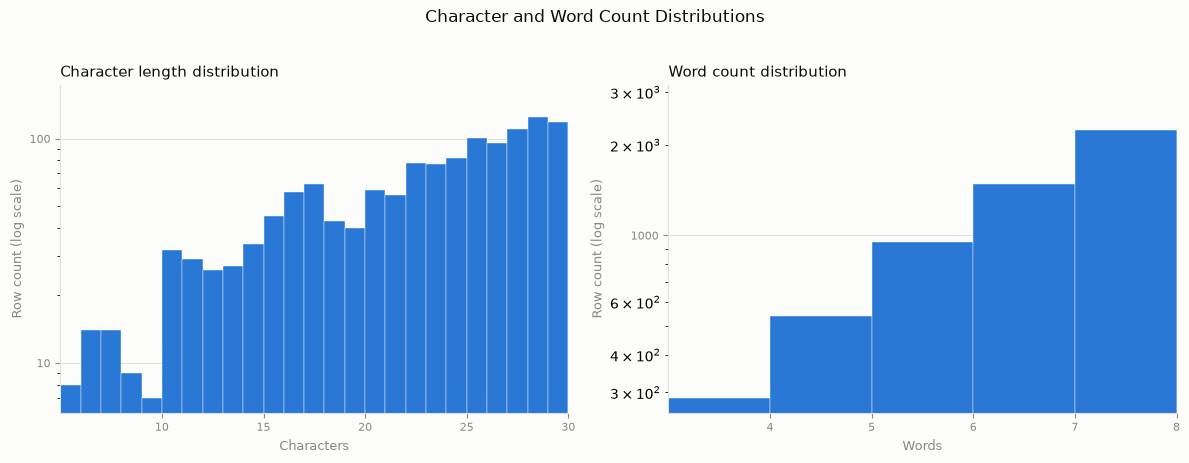

In [20]:
#Distribution chart for char_len / word_count, zoomed to the candidate threshold range
#(matches the sensitivity-check candidates: 10/15/20/25/30 chars, 4/5/6/7/8 words).
#Uses preview_df / char_lengths / words from the cell above.
#No cutoff line - candidate values are marked as x-axis ticks instead, so the bars around
#each candidate are easy to read directly off the distribution.
#Char axis is capped at 30 (the highest candidate) rather than padded past it, to avoid
#a wall of empty/near-empty bins at the right edge.

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"
BLUE = "#2a78d6"

char_candidates = [10, 15, 20, 25, 30]
word_candidates = [4, 5, 6, 7, 8]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), facecolor=SURFACE)

for ax, data, candidates, title, xlabel in [
    (axes[0], char_lengths, char_candidates, "Character length distribution", "Characters"),
    (axes[1], words, word_candidates, "Word count distribution", "Words"),
]:
    xmin, xmax = min(candidates), max(candidates)
    left_pad = max(1, (xmax - xmin) // 4)
    data_in_range = data[(data >= xmin - left_pad) & (data <= xmax)]

    ax.set_facecolor(SURFACE)
    ax.hist(
        data_in_range,
        bins=range(xmin - left_pad, xmax + 2),
        color=BLUE,
        edgecolor=SURFACE,
        linewidth=0.3,
        zorder=2,
    )
    ax.set_xlim(xmin - left_pad, xmax)
    ax.set_xticks(candidates)
    ax.set_yscale("log")
    ax.set_title(title, color=INK, fontsize=11, loc="left")
    ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    ax.set_ylabel("Row count (log scale)", color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.grid(axis="y", color=GRID, linewidth=0.7, zorder=0)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_color(GRID)
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.yaxis.get_major_formatter().set_scientific(False)

fig.suptitle("Character and Word Count Distributions", color=INK, fontsize=12, y=1.02)
fig.tight_layout()
plt.show()

In [11]:
#apply explicit mapping for df1
apply_label_mapping(df1, source_col="topic", out_col="category_8", label_map=DF1_LABEL_MAP)

Labels not in map for 'topic' (assigned to Undefined): 769
  pets_animals_wildlife: 268
  US Crime, Violence, Terrorism & cybercrime: 227
  Nonprofit, Charities, & Fundraising: 96
  Discover: 95
  US Police Misconduct: 83
Rows: 22463
Nulls in category_8: 0
['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'Undefined', 'World']
category_8
Politics         4079
Business         3776
Science          3491
Entertainment    2808
Health           2557
Technology       2343
Sports           2197
Undefined         769
World             443
Name: count, dtype: int64


In [12]:
#apply explicit mapping for df2
apply_label_mapping(df2, source_col="labels", out_col="category_8", label_map=DF2_LABEL_MAP)

Labels not in map for 'labels' (assigned to Undefined): 40736
  QUEER VOICES: 6347
  BLACK VOICES: 4583
  WOMEN: 3572
  CRIME: 3562
  IMPACT: 3484
  DIVORCE: 3426
  MEDIA: 2944
  WEIRD NEWS: 2777
  RELIGION: 2577
  FIFTY: 1401
  GOOD NEWS: 1398
  U.S. NEWS: 1377
  COLLEGE: 1144
  LATINO VOICES: 1130
  EDUCATION: 1014
Rows: 209527
Nulls in category_8: 0
['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'Undefined', 'World']
category_8
Entertainment    77807
Undefined        40736
Politics         35602
Health           24639
World             9542
Business          7748
Science           6272
Sports            5077
Technology        2104
Name: count, dtype: int64


In [13]:
#apply explicit mapping for df3
apply_label_mapping(df3, source_col="label_text", out_col="category_8", label_map=DF3_LABEL_MAP)

Labels not in map for 'label_text': 0
Rows: 1225
Nulls in category_8: 0
['Business', 'Entertainment', 'Politics', 'Sports', 'Technology']
category_8
Business         286
Sports           275
Politics         242
Technology       212
Entertainment    210
Name: count, dtype: int64


In [14]:
#apply explicit mapping for df4
apply_label_mapping(df4, source_col="label_text", out_col="category_8", label_map=DF4_LABEL_MAP)

Labels not in map for 'label_text' (assigned to Undefined): 3233
  soc.religion.christian: 599
  rec.motorcycles: 598
  rec.autos: 594
  misc.forsale: 585
  alt.atheism: 480
  talk.religion.misc: 377
Rows: 11314
Nulls in category_8: 0
['Health', 'Politics', 'Science', 'Sports', 'Technology', 'Undefined']
category_8
Technology    4122
Undefined     3233
Politics      1575
Sports        1197
Health         594
Science        593
Name: count, dtype: int64


In [15]:
#apply direct mapping for df5 (AG News numeric labels 0-3 -> AG_NEWS_LABEL_MAP)
df5["category_8_raw"] = df5["label"]
df5["category_8"] = df5["label"].map(AG_NEWS_LABEL_MAP).fillna("Undefined")

unmatched_mask = ~df5["label"].isin(AG_NEWS_LABEL_MAP.keys()) & df5["label"].notna()
unmatched_counts = df5.loc[unmatched_mask, "label"].astype(str).value_counts()

if len(unmatched_counts) > 0:
    print(f"Unmatched labels in 'label': {int(unmatched_counts.sum())}")
    print(unmatched_counts)
    print("Unknown labels were assigned to Undefined.")
else:
    print("Unmatched labels in 'label': 0")

print(f"Rows: {len(df5)}")
print(f"Nulls in category_8: {int(df5['category_8'].isna().sum())}")
print(sorted(df5["category_8"].dropna().unique().tolist()))
print(df5["category_8"].value_counts(dropna=False))


Unmatched labels in 'label': 0
Rows: 120000
Nulls in category_8: 0
['Business', 'Sports', 'Technology', 'World']
category_8
Business      30000
Technology    30000
Sports        30000
World         30000
Name: count, dtype: int64


In [16]:
#confirm categories in each dataset after mapping
frames = {
    "df": df,
    "df1": df1,
    "df2": df2,
    "df3": df3,
    "df4": df4,
    "df5": df5,
}

for name, frame in frames.items():
    if "category_8" in frame.columns:
        uniques = sorted(frame["category_8"].dropna().unique().tolist())
        print(f"{name}: {len(uniques)} categories -> {uniques}")
    elif "Category_clean" in frame.columns:
        uniques = sorted(frame["Category_clean"].dropna().unique().tolist())
        print(f"{name}: {len(uniques)} categories -> {uniques}")
    else:
        print(f"{name}: no cleaned category column yet")

df: 8 categories -> ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'World']
df1: 9 categories -> ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'Undefined', 'World']
df2: 9 categories -> ['Business', 'Entertainment', 'Health', 'Politics', 'Science', 'Sports', 'Technology', 'Undefined', 'World']
df3: 5 categories -> ['Business', 'Entertainment', 'Politics', 'Sports', 'Technology']
df4: 6 categories -> ['Health', 'Politics', 'Science', 'Sports', 'Technology', 'Undefined']
df5: 4 categories -> ['Business', 'Sports', 'Technology', 'World']


In [17]:
#merge all 6 clean datasets into one file and export 

def _pick_text_series(df_in, source_name):
    """Each source stores its article text under a different column name -
    pick the right one per source. HuffPost-style sources (df2) store
    headline and short_description separately and need them combined."""
    if {"headline", "short_description"}.issubset(df_in.columns):
        print(f"{source_name}: using combined 'headline' + 'short_description'")
        headline = df_in["headline"].fillna("").astype(str).str.strip()
        short_desc = df_in["short_description"].fillna("").astype(str).str.strip()
        return (headline + " " + short_desc).str.strip()

    text_candidates = [
        "Text", "text", "article_text", "content", "article", "description", "summary", "title"
    ]
    for col in text_candidates:
        if col in df_in.columns:
            print(f"{source_name}: using text column '{col}'")
            return df_in[col].fillna("").astype(str).str.strip()

    # pandas 3's native "str" dtype (and pyarrow-backed string columns from `datasets`) don't satisfy `dtype == "object"`, so check more broadly.
    obj_cols = [c for c in df_in.columns if pd.api.types.is_string_dtype(df_in[c])]
    if obj_cols:
        print(f"{source_name}: fallback to first string column '{obj_cols[0]}'")
        return df_in[obj_cols[0]].fillna("").astype(str).str.strip()

    print(f"{source_name}: WARNING - no text column found, using empty strings")
    return pd.Series([""] * len(df_in), index=df_in.index)


def _build_unified_part(df_in, source_name):
    if "category_8" in df_in.columns:
        category = df_in["category_8"]
    elif "Category_clean" in df_in.columns:
        category = df_in["Category_clean"]
    else:
        raise KeyError(f"No cleaned category column found in {source_name}")

    out = pd.DataFrame({
        "text": _pick_text_series(df_in, source_name),
        "category": category.astype(str).str.strip(),
        "category_8_raw": df_in["category_8_raw"] if "category_8_raw" in df_in.columns else pd.NA,
        "source_dataset": source_name,
    })

    out["text"] = clean_text_series(out["text"])
    out = out[out["text"].str.len() >= 20]
    out = out[word_count_series(out["text"]) >= 6]
    out = out[out["category"].isin(TARGET_CATEGORIES)]
    out = out.dropna(subset=["category", "text"])
    out = out.drop_duplicates(subset=["text"], keep="first")
    return out.reset_index(drop=True)


# Cross-source dedup keeps the FIRST occurrence by text (drop_duplicates(keep="first")).
# parts list order below is the deterministic tiebreak: df > df1 > df2 > df3 > df4 > df5.
# i.e. when the same text appears in multiple sources, the earlier-listed source wins and
# is what ends up in source_dataset for that row.
parts = [
    _build_unified_part(df, "df"),
    _build_unified_part(df1, "df1"),
    _build_unified_part(df2, "df2"),
    _build_unified_part(df3, "df3"),
    _build_unified_part(df4, "df4"),
    _build_unified_part(df5, "df5"),
]

#drop duplicates across all datasets based on the "text" column, keeping the first occurrence
big_df = pd.concat(parts, ignore_index=True)
rows_before_dedup = len(big_df)
big_df = big_df.drop_duplicates(subset=["text"], keep="first").reset_index(drop=True)
rows_after_dedup = len(big_df)

print("Unified shape (after cleaning and dedup):", big_df.shape)
print(f"Duplicates removed by text: {rows_before_dedup - rows_after_dedup}")

print("\nCategory distribution:")
print(big_df["category"].value_counts())
print("\nSource distribution:")
print(big_df["source_dataset"].value_counts())

#export into csv file
export_path = "../data/data_final.csv"
big_df.to_csv(export_path, index=False, encoding="utf-8")
print(f"\nExported to: {export_path}")

# STEP 13: Post-export sanity checks - class balance, per-source/category breakdown, text length distribution, leftover encoding artifacts, and a few manual samples to eyeball for mapping quality.

print("=== 1. Class balance ===")
counts = big_df["category"].value_counts()
print(counts)
print(f"Imbalance ratio (max/min): {counts.max() / counts.min():.1f}x")

print("\n=== 2. Source contribution per category ===")
print(pd.crosstab(big_df["source_dataset"], big_df["category"]))

print("\n=== 3. Text length distribution ===")
lengths = big_df["text"].str.len()
print(lengths.describe())
print(f"Rows under 20 chars: {(lengths < 20).sum()}")
word_counts = big_df["text"].fillna("").astype(str).str.split().str.len()
print(f"Rows under 6 words: {(word_counts < 6).sum()}")
print(f"Rows over 5000 chars: {(lengths > 5000).sum()}")

print("\n=== 4. Residual encoding issues ===")
suspect_chars = ["â€", "Â", "�"]
for ch in suspect_chars:
    n = big_df["text"].str.contains(re.escape(ch), na=False).sum()
    print(f"  '{ch}': {n} rows")

print("\n=== 5. Random sample for manual eyeballing ===")
print(big_df.sample(10, random_state=42)[["category", "text"]].to_string(max_colwidth=100))

print("\n=== 6. World sample with raw labels ===")
world_sample = big_df[big_df["category"] == "World"].sort_values("text", key=lambda s: s.str.len()).head(20)
print(world_sample[["text", "category_8_raw", "category"]].to_string(max_colwidth=100))

print("\n=== 7. Entertainment sample with raw labels ===")
ent_sample = big_df[big_df["category"] == "Entertainment"].sort_values("text", key=lambda s: s.str.len()).head(20)
print(ent_sample[["text", "category_8_raw", "category"]].to_string(max_colwidth=100))

print("\n=== 8. Near-duplicate check (same text, different category) ===")
conflicts = big_df.groupby("text")["category"].nunique()
print(f"Texts with conflicting category labels: {(conflicts > 1).sum()}")

df: using text column 'Text'
df1: using text column 'article_text'
df2: using text column 'text'
df3: using text column 'text'
df4: using text column 'text'
df5: using text column 'text'
Unified shape (after cleaning and dedup): (365226, 4)
Duplicates removed by text: 0

Category distribution:
category
Entertainment    80426
Undefined        44042
Business         42152
Politics         41587
World            40440
Sports           39025
Technology       38851
Health           27978
Science          10725
Name: count, dtype: int64

Source distribution:
source_dataset
df2    207152
df5    119911
df1     22419
df4     10832
df       3718
df3      1194
Name: count, dtype: int64

Exported to: ../data/data_final.csv
=== 1. Class balance ===
category
Entertainment    80426
Undefined        44042
Business         42152
Politics         41587
World            40440
Sports           39025
Technology       38851
Health           27978
Science          10725
Name: count, dtype: int64
Imbalance ra